Scaled Dot-Product Self-Attention mechanism using Python and NumPy

In [ ]:
import numpy as np

np.set_printoptions(precision=3, suppress=True)

# Input embeddings
X = np.array([
    [1, 0, 1, 0],
    [0, 2, 0, 2],
    [1, 1, 1, 1],
    [2, 0, 2, 0]
], dtype=np.float32)

# Reproducible initialization
np.random.seed(42)

# Learnable projection matrices
W_Q = np.random.randn(4, 4)
W_K = np.random.randn(4, 4)
W_V = np.random.randn(4, 4)

# Generate Query, Key, Value
Q = X @ W_Q
K = X @ W_K
V = X @ W_V

print("Query:\n", Q)
print("Key:\n", K)
print("Value:\n", V)


Query:
 [[ 0.027  0.404  0.184  1.057]
 [ 0.016 -4.295 -0.291  0.41 ]
 [ 0.035 -1.743  0.039  1.262]
 [ 0.054  0.809  0.369  2.115]]
Key:
 [[-1.557  0.425 -2.059 -1.037]
 [ 1.73  -1.035 -1.068  0.855]
 [-0.692 -0.092 -2.593 -0.609]
 [-3.114  0.85  -4.118 -2.073]]
Value:
 [[ 0.725 -0.886  0.707 -1.522]
 [-2.539 -5.359 -3.578  2.508]
 [-0.545 -3.566 -1.082 -0.268]
 [ 1.45  -1.773  1.414 -3.044]]
Attention Scores:
[[-1.346  0.336 -1.178 -2.692]
 [-1.676  5.134  0.891 -3.351]
 [-2.184  2.903 -0.732 -4.368]
 [-2.692  0.672 -2.356 -5.384]]


In [ ]:
scores = Q @ K.T

print("Attention Scores:")
print(scores)

In [ ]:
d_k = K.shape[-1]

scaled_scores = scores / np.sqrt(d_k)

print("Scaled Scores:")
print(scaled_scores)

Scaled Scores:
[[-0.673  0.168 -0.589 -1.346]
 [-0.838  2.567  0.446 -1.676]
 [-1.092  1.451 -0.366 -2.184]
 [-1.346  0.336 -1.178 -2.692]]


In [ ]:
def softmax(x, axis=-1):
    # Numerical stability
    x = x - np.max(x, axis=axis, keepdims=True)

    exp_x = np.exp(x)

    return exp_x / np.sum(
        exp_x,
        axis=axis,
        keepdims=True
    )

In [ ]:
attention_weights = softmax(scaled_scores)

print("Attention Weights:")
print(attention_weights)

print("Row sums:")
print(attention_weights.sum(axis=1))

Attention Weights:
[[0.203 0.472 0.221 0.104]
 [0.028 0.857 0.103 0.012]
 [0.062 0.789 0.128 0.021]
 [0.128 0.688 0.151 0.033]]
Row sums:
[1. 1. 1. 1.]


In [ ]:
output = attention_weights @ V

print("Final Attention Output:")
print(output)

Final Attention Output:
[[-1.02  -3.68  -1.636  0.498]
 [-2.193 -5.004 -3.138  2.04 ]
 [-1.998 -4.777 -2.888  1.787]
 [-1.687 -4.396 -2.486  1.388]]


# Togather

In [ ]:
result = np.linalg.matrix_power(A, n)

In [ ]:

import numpy as np


def softmax(x, axis=-1):
    """Numerically stable softmax."""
    x = x - np.max(x, axis=axis, keepdims=True)
    exp_x = np.exp(x)
    return exp_x / np.sum(exp_x, axis=axis, keepdims=True)


def self_attention(X, W_Q, W_K, W_V):
    """
    Scaled Dot-Product Self-Attention.

    X:   (sequence_length, embedding_dim)
    W_Q: (embedding_dim, key_dim)
    W_K: (embedding_dim, key_dim)
    W_V: (embedding_dim, value_dim)
    """

    # 1. Linear projections
    Q = X @ W_Q
    K = X @ W_K
    V = X @ W_V

    # Q = np.linalg.matrix_power(Q, 8)
    # K = np.linalg.matrix_power(K, 8)
    # V = np.linalg.matrix_power(V, 8)
    print("Q=")
    print(Q)
    print("K")
    print(K)
    print("V")
    print(V)

    # 2. Attention scores
    scores = Q @ K.T

    # 3. Scale
    d_k = K.shape[-1]
    scaled_scores = scores / np.sqrt(d_k)

    #scaled_scores = np.linalg.matrix_power(scaled_scores, 4)
    # scaled_scores = scaled_scores / 16.0

    # 4. Softmax
    weights = softmax(scaled_scores)

    # 5. Weighted sum of values
    output = weights @ V

    return output, weights


# Example input
X = np.array([
    [1, 0, 1, 0, 1, 0, 1, 0],
    [0, 2, 0, 2, 0, 2, 0, 2],
    [0, 2, 1, 2, 1, 2, 0, 2],
    [1, 1, 1, 1, 1, 1, 1, 1],
    [1, 0, 0, 2, 1, 2, 1, 2],
    [2, 0, 2, 0, 2, 0, 2, 0]
], dtype=np.float32)

np.random.seed(42)

W_Q = np.random.randn(8, 8)
W_K = np.random.randn(8, 8)
W_V = np.random.randn(8, 8)

output, weights = self_attention(
    X, W_Q, W_K, W_V
)

print("Attention Weights:\n", weights)
print("Output:\n", output)

assert output.shape == X.shape
assert np.allclose(weights.sum(axis=-1), 1.0)

print(weights.sum(axis=-1))

print("Self-Attention completed successfully!")


Q=
[[-0.1859959  -2.64476805  0.88629334 -1.49519978  0.76343699 -1.80790709
   1.34955449  0.4708279 ]
 [-2.22921611  1.03127708 -2.79759224  1.16881939 -4.63274529 -6.22095436
  -7.78719638  2.30181251]
 [-3.25554445  0.28781348 -2.88307141 -1.46432796 -2.95823293 -8.40640078
  -9.04785422  1.07392556]
 [-1.30060396 -2.12912951 -0.51250278 -0.91079008 -1.55293566 -4.91838427
  -2.5440437   1.62173416]
 [-0.46343212 -3.0128584  -0.07643944  2.01738283 -5.81888162 -3.97652466
  -3.05533443  5.32196366]
 [-0.3719918  -5.28953611  1.77258669 -2.99039955  1.52687398 -3.61581418
   2.69910899  0.9416558 ]]
K
[[ 0.94920442  4.43764998  1.21863642  0.55222289 -1.89694009 -2.73620016
   2.07690602  1.81644344]
 [ 0.12831999  3.14514898  1.53262531  1.12654849  0.45880292  2.97868043
  -6.41930983 -8.08779094]
 [ 0.20476837  3.76331683  3.01563282  0.37369114 -1.76506143  2.05627806
  -5.84662223 -8.5613171 ]
 [ 1.01336441  6.01022448  1.98494907  1.11549713 -1.66753863 -1.24685995
  -1.132748

Casual attention

In [ ]:
def causal_mask(seq_len):
    mask = np.triu(
        np.ones((seq_len, seq_len)),
        k=1
    )

    return np.where(mask == 1, -np.inf, 0.0)

In [ ]:
def causal_self_attention(X, W_Q, W_K, W_V):

    Q = X @ W_Q
    K = X @ W_K
    V = X @ W_V

    d_k = K.shape[-1]

    scores = (Q @ K.T) / np.sqrt(d_k)

    # Prevent access to future tokens
    mask = causal_mask(X.shape[0])

    scores = scores + mask

    weights = softmax(scores)

    output = weights @ V

    return output, weights

In [ ]:
ca_output, ca_weights = causal_self_attention(X, W_Q, W_K, W_V)

print(weights,end="\n\n")
print(ca_weights,end="\n\n")

[[8.17138250e-01 3.84245406e-04 6.10744073e-04 7.99503776e-03
  7.51806470e-03 1.66353658e-01]
 [7.58919149e-03 2.80848174e-03 2.28519940e-02 5.03350336e-02
  1.42853074e-02 9.02129992e-01]
 [1.80902195e-03 1.16466074e-01 7.85455488e-01 3.93205061e-02
  4.36737806e-02 1.32751295e-02]
 [3.06842773e-01 8.77742422e-05 3.97964116e-04 7.73175891e-03
  3.87323152e-03 6.81066498e-01]
 [1.21031549e-02 1.62830642e-11 3.66644202e-10 4.01071821e-06
  3.80024623e-06 9.87889034e-01]
 [9.60037203e-01 2.12282577e-07 5.36309517e-07 9.19047633e-05
  8.12660405e-05 3.97888779e-02]]

[[1.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [7.29893249e-01 2.70106751e-01 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [2.00172705e-03 1.28872560e-01 8.69125713e-01 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [9.73917698e-01 2.78595083e-04 1.26313647e-03 2.45405709e-02
  0.00000000e+00 0.00000000e+00]
 [9.99355019e-01 1.34448927e-09 3.02737366e-08 3

# Multi headed attention

In [ ]:
!pip install torch numpy matplotlib

In [ ]:

import torch
import torch.nn as nn
import math


class MultiHeadAttention(nn.Module):

    def __init__(self, embed_dim, num_heads, causal=False):

        super().__init__()

        assert embed_dim % num_heads == 0, \
            "Embedding dimension must be divisible by heads"

        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        self.causal = causal

        # Learnable projections
        self.W_Q = nn.Linear(embed_dim, embed_dim)
        self.W_K = nn.Linear(embed_dim, embed_dim)
        self.W_V = nn.Linear(embed_dim, embed_dim)

        # Combine attention heads
        self.W_O = nn.Linear(embed_dim, embed_dim)

    def forward(self, x):

        batch_size, seq_len, embed_dim = x.shape

        # 1. Generate Q, K, V
        Q = self.W_Q(x)
        K = self.W_K(x)
        V = self.W_V(x)

        # 2. Split embedding dimensions into heads
        Q = Q.view(
            batch_size, seq_len,
            self.num_heads, self.head_dim
        ).transpose(1, 2)

        K = K.view(
            batch_size, seq_len,
            self.num_heads, self.head_dim
        ).transpose(1, 2)

        V = V.view(
            batch_size, seq_len,
            self.num_heads, self.head_dim
        ).transpose(1, 2)

        # Shapes: (batch, heads, sequence, head_dim)

        # 3. Calculate attention scores
        scores = Q @ K.transpose(-2, -1)

        # 4. Scale scores
        scores = scores / math.sqrt(self.head_dim)

        # 5. Apply causal mask if required
        if self.causal:
            mask = torch.triu(
                torch.ones(
                    seq_len, seq_len,
                    device=x.device,
                    dtype=torch.bool
                ),
                diagonal=1
            )

            scores = scores.masked_fill(mask, float("-inf"))

        # 6. Softmax
        weights = torch.softmax(scores, dim=-1)

        # 7. Weighted sum of values
        attention = weights @ V

        # 8. Merge all heads
        attention = attention.transpose(1, 2).contiguous()

        attention = attention.view(batch_size, seq_len, self.embed_dim)

        # 9. Final output projection
        output = self.W_O(attention)

        return output, weights


In [ ]:
# Configuration
batch_size = 2
seq_len = 5
embed_dim = 128
num_heads = 8

# Random input
x = torch.randn(
    batch_size,
    seq_len,
    embed_dim
)

# Create attention layer
attention = MultiHeadAttention(
    embed_dim=embed_dim,
    num_heads=num_heads,
    causal=True
)

# Forward pass
output, weights = attention(x)

print("Input:", x.shape)
print("Output:", output.shape)
print("Attention weights:", weights.shape)

Input: torch.Size([2, 5, 128])
Output: torch.Size([2, 5, 128])
Attention weights: torch.Size([2, 8, 5, 5])


In [ ]:
print(weights[0, 0])

assert torch.allclose(
    weights.triu(diagonal=1),
    torch.zeros_like(weights),
    atol=1e-6
)

print("Causal masking verified!")

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5947, 0.4053, 0.0000, 0.0000, 0.0000],
        [0.2722, 0.3410, 0.3867, 0.0000, 0.0000],
        [0.2548, 0.2645, 0.2455, 0.2351, 0.0000],
        [0.2311, 0.1783, 0.1920, 0.1912, 0.2074]], grad_fn=<SelectBackward0>)
Causal masking verified!


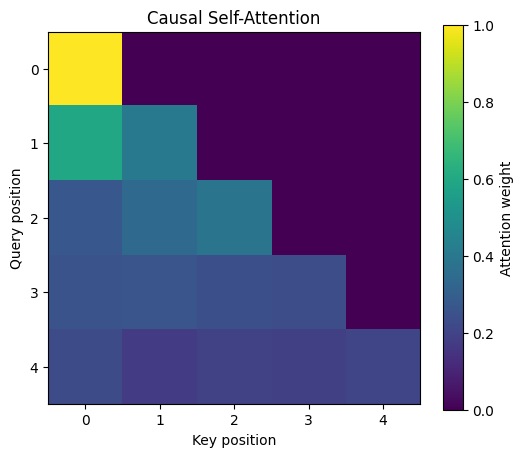

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))

plt.imshow(
    weights[0, 0].detach().numpy(),
    cmap="viridis"
)

plt.colorbar(label="Attention weight")

plt.xlabel("Key position")
plt.ylabel("Query position")
plt.title("Causal Self-Attention")

plt.show()

In [ ]:
# Create a learnable attention model
model = MultiHeadAttention(
    embed_dim=128,
    num_heads=8,
    causal=True
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001
)

# Example input and target
x = torch.randn(2, 5, 128)
target = torch.randn(2, 5, 128)

# Forward pass
output, weights = model(x)

# Calculate loss
loss = nn.functional.mse_loss(output, target)

# Backpropagation
optimizer.zero_grad()
loss.backward()

# Update parameters
optimizer.step()

print("Loss:", loss.item())
print("Training step completed!")

Loss: 1.0335924625396729
Training step completed!
